# 5 · Chapter 5 and Appendix A: the Magic Formula tyre model

Code: `okane/tyre.py` (Magic Formula, relaxation, coupling), `okane/params.py` (tyre profile), `okane/analysis.py` (`BikeSystem`: model + force blocks + tyres),
`okane/benchmark.py` (independent check of the lateral dynamics).

**Data.** [T] = thesis Tables 5.1–5.5 (force parameters), 5.6–5.10 (profile). The thesis does not give the nominal loads, the pneumatic-trail
parameters, the carcass stiffnesses for relaxation or the radial stiffness. These are taken from the paper the thesis' tyre data come from,
[S] = Sharp, Evangelou & Limebeer, *Multibody Syst. Dyn.* 12 (2004): $F_{z0}$ = 1100 / 1600 N, Table III trail parameters, relaxation
$\sigma_y=K_{y\alpha}\cdot8.633\cdot10^{-6}$ (front) and $9.694\cdot10^{-6}$ (rear), radial stiffness 130 / 141 kN/m. Longitudinal carcass stiffness is an estimate [E].

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))   # repo root (not needed after `pip install -e .`)
import numpy as np, matplotlib.pyplot as plt, time
from okane.params import cbr600rr_estimate, PROFILE_THESIS
from okane.kinematics import make_q
from okane.model import Motorcycle, rk4, IIN
from okane.forces import ForceSet
from okane.tyre import MagicFormula, TyreSet, front_tyre, rear_tyre, _mf_sin, _mf_cos
from okane.analysis import BikeSystem, lateral_modes
from okane import benchmark
from okane.plotting import use_style, C
use_style(); deg = np.degrees; rad = np.radians
front, rear = MagicFormula(front_tyre()), MagicFormula(rear_tyre())            # Table 5.5 values applied
front0, rear0 = MagicFormula(front_tyre(False)), MagicFormula(rear_tyre(False))  # Tables 5.1-5.4

## 5.1–5.2 Conventions and slip quantities
The thesis negates $p_{Ky1}$ and $p_{Ky6}$ of Sharp et al., so its equations work in the ISO tyre system ($y$ to the left). With the model's axes
(3 = right) this means:

| quantity | definition | sign |
|---|---|---|
| longitudinal slip (5.3) | $\kappa=-V_{sx}/|V_x|$ | + when driving |
| lateral slip (5.4) | $\alpha^*=\tan\alpha=-V_{sy}/|V_x|$, $V_{sy}$ to the right | + when the contact point slides to the **left** |
| camber | $\gamma$ | + when the wheel leans to the **right** |
| Magic Formula $F_y$ | Appendix A | + to the **left**; the model input is $F_{y,model}=-F_y$ |

$K_{y\alpha}<0$: sliding left gives a force to the right. $K_{y\gamma}<0$: leaning right gives a force to the right. In all plots below the lateral force is
shown in model axes (positive to the right, i.e. towards the lean side for positive camber).

## 5.3 The sine and cosine formula (Figs. 5.9, 5.11)

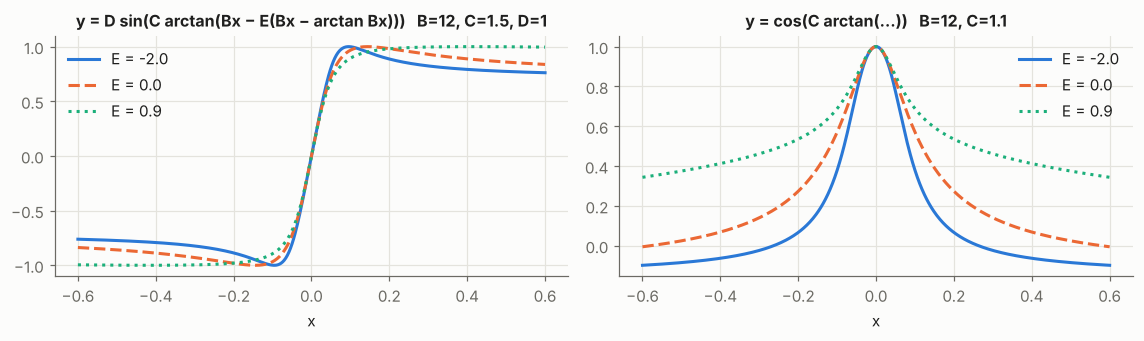

In [2]:
x = np.linspace(-0.6, 0.6, 601)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
for i, (E, ls) in enumerate([(-2.0, "-"), (0.0, "--"), (0.9, ":")]):
    ax[0].plot(x, _mf_sin(12, 1.5, 1.0, E, x), ls, color=C[i], label=f"E = {E}")
    ax[1].plot(x, _mf_cos(12, 1.1, E, x), ls, color=C[i], label=f"E = {E}")
ax[0].set_title("y = D sin(C arctan(Bx − E(Bx − arctan Bx)))   B=12, C=1.5, D=1"); ax[1].set_title("y = cos(C arctan(...))   B=12, C=1.1")
for a in ax: a.set_xlabel("x"); a.legend()
plt.tight_layout()

## 5.4 Parameters and basic characteristics (Figs. 5.2, 5.13)

front 120/70: Fz0 = 1100 N | Kx_kappa = 22.0 kN | Ky_alpha = -55.0 kN/rad | camber stiffness = -0.99 kN/rad | mu_x = 1.44, mu_y = 1.67 | relaxation dx = 73 mm, dy = 475 mm | trail at zero slip = 60 mm
rear 180/55: Fz0 = 1600 N | Kx_kappa = 41.5 kN | Ky_alpha = -38.3 kN/rad | camber stiffness = -1.20 kN/rad | mu_x = 1.50, mu_y = 1.56 | relaxation dx = 119 mm, dy = 371 mm | trail at zero slip = 84 mm


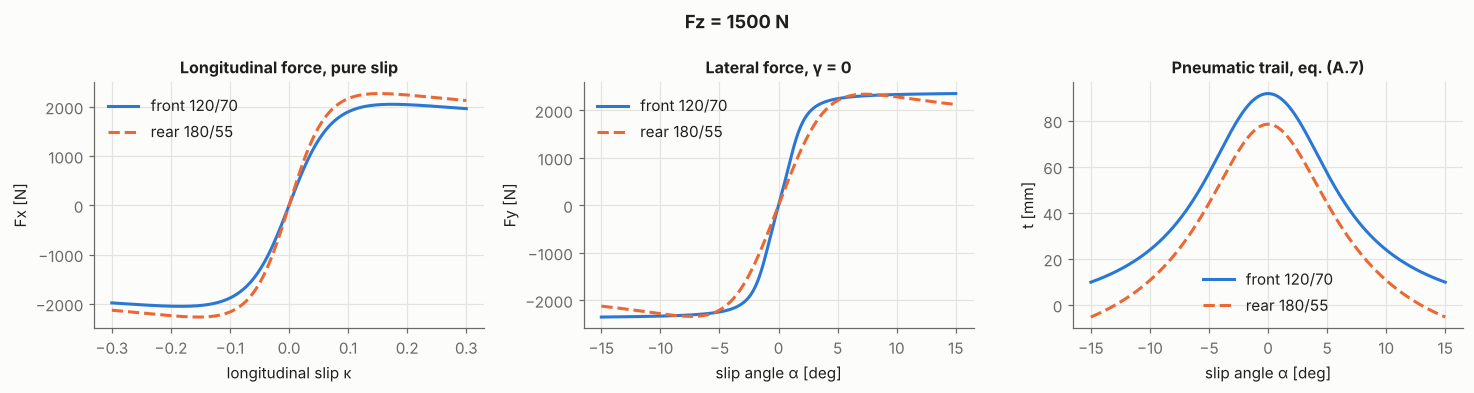

In [3]:
for T in (front, rear):
    Fz = T.p.Fz0
    Kya, Kyg = T.stiffness(0.0, Fz); dx, dy = T.relaxation_lengths(Fz)
    print(f"{T.p.name}: Fz0 = {Fz:.0f} N | Kx_kappa = {Fz*T.p.pKx1/1e3:.1f} kN | Ky_alpha = {Kya/1e3:.1f} kN/rad | camber stiffness = {Kyg/1e3:.2f} kN/rad"
          f" | mu_x = {T.p.pDx1:.2f}, mu_y = {T.p.pDy1:.2f} | relaxation dx = {dx*1e3:.0f} mm, dy = {dy*1e3:.0f} mm | trail at zero slip = {T.pneumatic_trail(0,0,0,Fz)*1e3:.0f} mm")

kap = np.linspace(-0.3, 0.3, 601); al = rad(np.linspace(-15, 15, 601)); Fz = 1500.0
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6))
for i, (T, lab) in enumerate([(front, "front 120/70"), (rear, "rear 180/55")]):
    ax[0].plot(kap, T.forces(kap, 0.0, 0.0, Fz)[0], color=C[i], ls=["-", "--"][i], label=lab)
    ax[1].plot(deg(al), -T.forces(0.0, np.tan(al), 0.0, Fz)[1], color=C[i], ls=["-", "--"][i], label=lab)
    ax[2].plot(deg(al), 1e3 * T.pneumatic_trail(0.0, np.tan(al), 0.0, Fz), color=C[i], ls=["-", "--"][i], label=lab)
ax[0].set_xlabel("longitudinal slip κ"); ax[0].set_ylabel("Fx [N]"); ax[0].set_title("Longitudinal force, pure slip")
ax[1].set_xlabel("slip angle α [deg]"); ax[1].set_ylabel("Fy [N]"); ax[1].set_title("Lateral force, γ = 0")
ax[2].set_xlabel("slip angle α [deg]"); ax[2].set_ylabel("t [mm]"); ax[2].set_title("Pneumatic trail, eq. (A.7)")
for a in ax: a.legend()
fig.suptitle("Fz = 1500 N", fontweight="bold"); plt.tight_layout()

### 5.2.6 Camber thrust (Fig. 5.7)
The thesis' example: $F_z$ = 1500 N; the lateral force needed for equilibrium at 50° is $F_z\tan50°$ = 1788 N.

slip angle needed for Fy = 1788 N        camber 0°   camber 50°   camber thrust at α = 0
   front, Table 5.2             4.89°       2.04°            932 N
   front, Table 5.5             2.12°       0.36°           1309 N
   rear, Table 5.4              3.37°       0.62°           1474 N
   rear, Table 5.5              3.27°       1.59°            986 N
   thesis text (Fig. 5.7)            6.2°        1.7°            ≈1100 N (read from the figure)


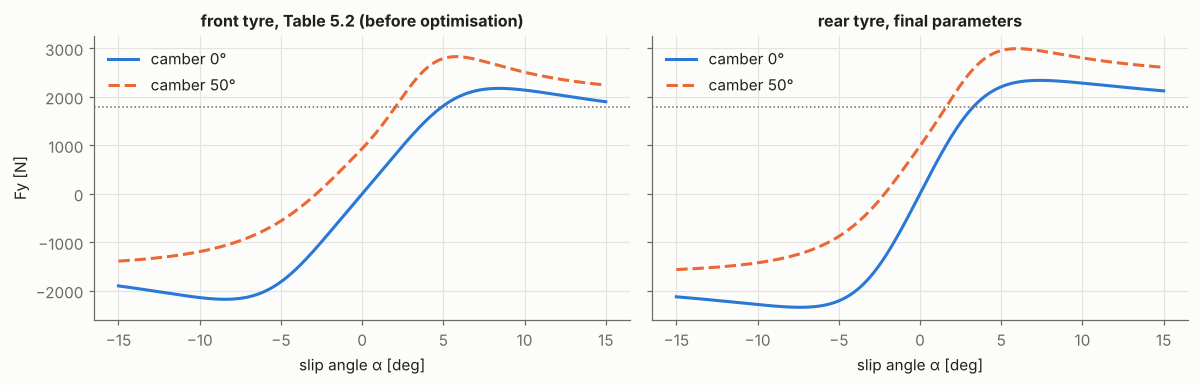

In [4]:
target = Fz * np.tan(rad(50)); a_pos = rad(np.linspace(0, 15, 3001))
def slip_needed(T, gam):
    Fy = -T.forces(0.0, np.tan(a_pos), gam, Fz)[1]
    return deg(a_pos[np.argmax(Fy >= target)]) if (Fy >= target).any() else np.nan
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, T in zip(ax, (front0, rear)):
    for i, gam in enumerate((0.0, rad(50))):
        a.plot(deg(al), -T.forces(0.0, np.tan(al), gam, Fz)[1], color=C[i], ls=["-", "--"][i], label=f"camber {deg(gam):.0f}°")
    a.axhline(target, color="#6b6a64", lw=1, ls=":"); a.set_xlabel("slip angle α [deg]"); a.legend()
ax[0].set_title("front tyre, Table 5.2 (before optimisation)"); ax[1].set_title("rear tyre, final parameters"); ax[0].set_ylabel("Fy [N]")
plt.tight_layout()
print("slip angle needed for Fy = 1788 N        camber 0°   camber 50°   camber thrust at α = 0")
for lab, T in [("front, Table 5.2", front0), ("front, Table 5.5", front), ("rear, Table 5.4", rear0), ("rear, Table 5.5", rear)]:
    print(f"   {lab:18s} {slip_needed(T, 0.0):14.2f}° {slip_needed(T, rad(50)):10.2f}° {float(-T.camber_thrust(0.0, rad(50), Fz)):14.0f} N")
print("   thesis text (Fig. 5.7)            6.2°        1.7°            ≈1100 N (read from the figure)")

Qualitatively as described in Section 5.2.6: camber thrust supplies most of the lateral force, raises the peak and moves it to a smaller slip angle.
The numbers do not match Fig. 5.7 for any of the four parameter sets. The peak of the thesis' zero-camber curve is about 1.25 $F_z$, i.e. the figure was
drawn with a lower friction coefficient than the $p_{Dy1}$ = 1.45…1.67 of Tables 5.2–5.5 (it resembles the original values of Sharp et al., $p_{Dy1}$ = 1.3).

### Combined slip (A.1.2, A.2.2)

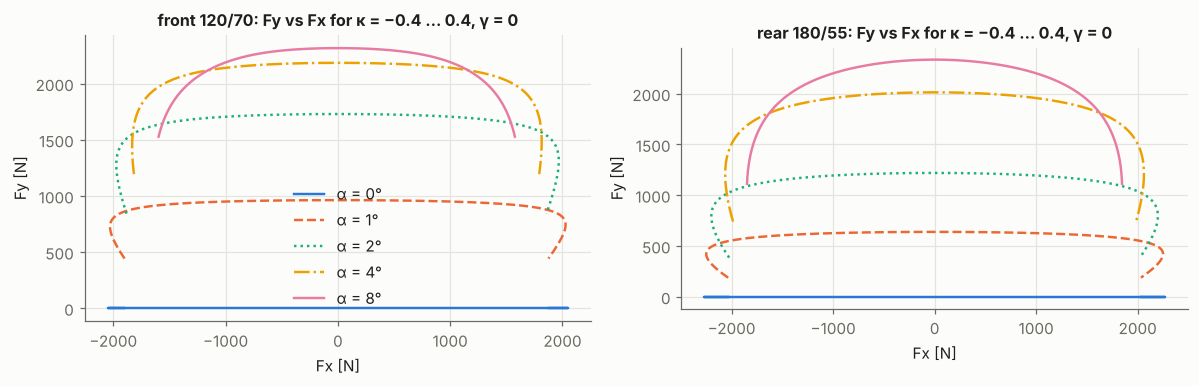

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
k_ = np.linspace(-0.4, 0.4, 801)
for a, T in zip(ax, (front, rear)):
    for i, adeg in enumerate((0, 1, 2, 4, 8)):
        Fx, Fy = T.forces(k_, np.tan(rad(adeg)), 0.0, Fz)
        a.plot(Fx, -Fy, color=C[i % len(C)], ls=["-", "--", ":", "-.", "-"][i], lw=1.6, label=f"α = {adeg}°")
    a.set_xlabel("Fx [N]"); a.set_ylabel("Fy [N]"); a.set_title(T.p.name + ": Fy vs Fx for κ = −0.4 … 0.4, γ = 0"); a.set_aspect("equal")
ax[0].legend(); plt.tight_layout()

### 5.4.1 Original and optimised lateral parameters (Table 5.5)
The thesis tunes nine front and two rear $F_y$ parameters until the model's steering angle at full lean matches the track data.

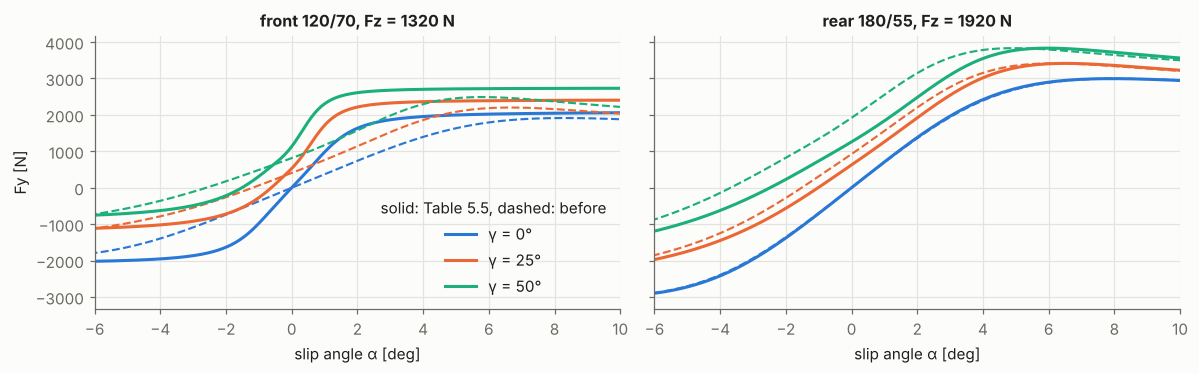

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, (T0, T1) in zip(ax, ((front0, front), (rear0, rear))):
    for i, gam in enumerate((0.0, rad(25), rad(50))):
        a.plot(deg(al), -T0.forces(0.0, np.tan(al), gam, T0.p.Fz0 * 1.2)[1], color=C[i], ls="--", lw=1.4)
        a.plot(deg(al), -T1.forces(0.0, np.tan(al), gam, T1.p.Fz0 * 1.2)[1], color=C[i], label=f"γ = {deg(gam):.0f}°")
    a.set_xlim(-6, 10); a.set_xlabel("slip angle α [deg]"); a.set_title(T1.p.name + f", Fz = {T1.p.Fz0*1.2:.0f} N")
ax[0].set_ylabel("Fy [N]"); ax[0].legend(title="solid: Table 5.5, dashed: before"); plt.tight_layout()

The front tyre becomes much stiffer in side-slip ($p_{Ky1}$: −22.8 → −50) with a higher camber stiffness; the rear loses camber stiffness ($p_{Ky6}$: −1.10 → −0.75),
so it has to run at a larger slip angle. Both changes move the bike towards oversteer, i.e. less steering angle into the turn (checked on the full model below).

## 5.2.16 / A.6 Relaxation
$\tau\dot F+F=F_{ss}$ with $\tau=\delta/|V_x|$, $\delta_x=K_{x\kappa}/C_x$, $\delta_y=|K_{y\alpha}|/C_y$. In `BikeSystem` the four lagged shear forces are extra states.

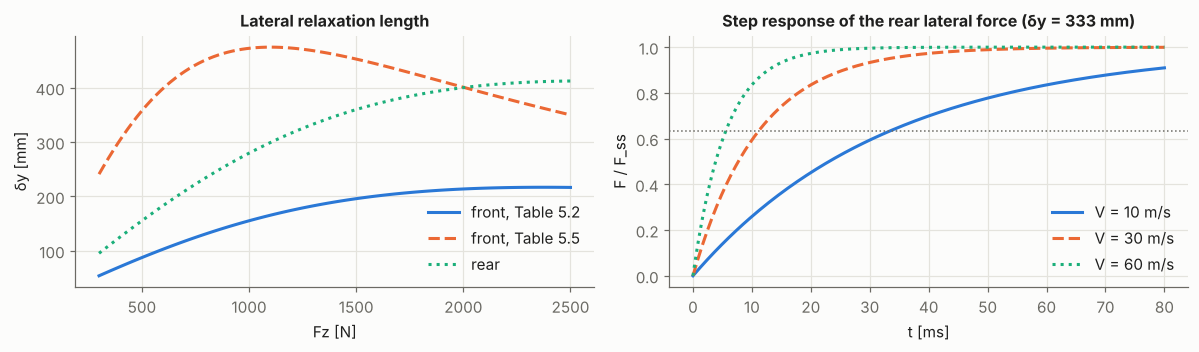

In [7]:
Fzs = np.linspace(300, 2500, 100)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for i, (T, lab) in enumerate([(front0, "front, Table 5.2"), (front, "front, Table 5.5"), (rear, "rear")]):
    ax[0].plot(Fzs, [T.relaxation_lengths(f)[1] * 1e3 for f in Fzs], color=C[i], ls=["-", "--", ":"][i], label=lab)
ax[0].set_xlabel("Fz [N]"); ax[0].set_ylabel("δy [mm]"); ax[0].legend(); ax[0].set_title("Lateral relaxation length")
t = np.linspace(0, 0.08, 200); dy = rear.relaxation_lengths(1300.0)[1]
for i, V in enumerate((10, 30, 60)):
    ax[1].plot(t * 1e3, 1 - np.exp(-t * V / dy), color=C[i], ls=["-", "--", ":"][i], label=f"V = {V} m/s")
ax[1].axhline(0.632, color="#6b6a64", lw=1, ls=":"); ax[1].set_xlabel("t [ms]"); ax[1].set_ylabel("F / F_ss"); ax[1].legend()
ax[1].set_title(f"Step response of the rear lateral force (δy = {dy*1e3:.0f} mm)")
plt.tight_layout()

Keeping the carcass stiffness $C_y$ of Sharp et al. while doubling $K_{y\alpha}$ (Table 5.5) more than doubles the front relaxation length, to almost 0.5 m at nominal load. That is long for a
120/70 tyre and it matters for wobble (below). The thesis gives no $C_y$, so treat this as an open parameter.

## 5.5 Tyre profile
Measured tangent points (Tables 5.7/5.8), the thesis' polynomials $y(\gamma)$, $z(\gamma)$ (5.18)/(5.19) with the coefficients of Tables 5.9/5.10, and the torus used in the
first session. The model now uses the polynomials by default (`cbr600rr_estimate(profile="measured")`).

T_z front = T_z rear at 50.5° camber   (thesis: 'around 50°')
front: max |dTz cosγ + dTy sinγ| = 2.52 mm/rad up to 55°
rear: max |dTz cosγ + dTy sinγ| = 6.02 mm/rad up to 55°


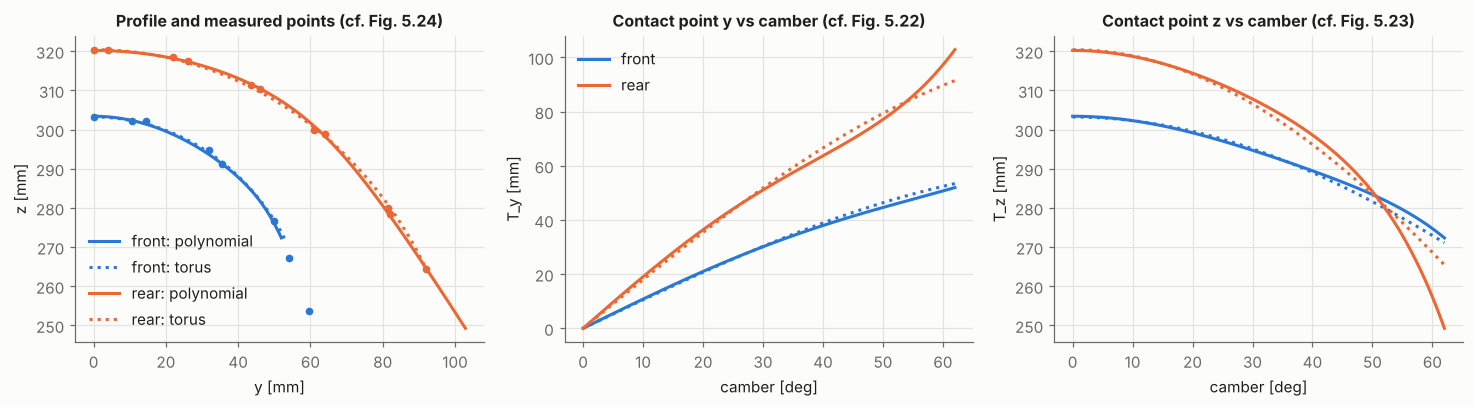

In [8]:
meas = dict(front=np.array([[0, 303.2], [10.5, 302.2], [14.5, 302.2], [32, 294.7], [35.5, 291.2], [50, 276.7], [54, 267.2], [59.5, 253.7]]),
            rear=np.array([[0, 320.4], [4, 320.4], [22, 318.4], [26, 317.4], [43.5, 311.4], [46, 310.4], [61, 299.9], [64, 298.9], [81.5, 279.9], [82, 278.4], [92, 264.4]]))
pm, _ = cbr600rr_estimate("measured"); pt, _ = cbr600rr_estimate("torus")
g = rad(np.linspace(0, 62, 200))
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.8))
for i, w in enumerate(("front", "rear")):
    ym, zm = pm.profile(w, g); yt, zt = pt.profile(w, g)
    ax[0].plot(meas[w][:, 0], meas[w][:, 1], "o", color=C[i], ms=4)
    ax[0].plot(ym * 1e3, zm * 1e3, color=C[i], label=f"{w}: polynomial"); ax[0].plot(yt * 1e3, zt * 1e3, ":", color=C[i], label=f"{w}: torus")
    ax[1].plot(deg(g), ym * 1e3, color=C[i], label=w); ax[1].plot(deg(g), yt * 1e3, ":", color=C[i])
    ax[2].plot(deg(g), zm * 1e3, color=C[i], label=w); ax[2].plot(deg(g), zt * 1e3, ":", color=C[i])
ax[0].set_xlabel("y [mm]"); ax[0].set_ylabel("z [mm]"); ax[0].set_title("Profile and measured points (cf. Fig. 5.24)"); ax[0].legend()
ax[1].set_xlabel("camber [deg]"); ax[1].set_ylabel("T_y [mm]"); ax[1].set_title("Contact point y vs camber (cf. Fig. 5.22)"); ax[1].legend()
ax[2].set_xlabel("camber [deg]"); ax[2].set_ylabel("T_z [mm]"); ax[2].set_title("Contact point z vs camber (cf. Fig. 5.23)")
plt.tight_layout()
zf, zr = pm.profile("front", g)[1], pm.profile("rear", g)[1]
print(f"T_z front = T_z rear at {deg(g[np.argmin(abs(zf - zr))]):.1f}° camber   (thesis: 'around 50°')")
# consistency of the polynomials: for a true contact point, dTz/dgamma * cos + dTy/dgamma * sin = 0
g55 = g[g <= rad(55)]
for w in ("front", "rear"):
    y_, z_ = pm.profile(w, g55); err = np.gradient(z_, g55) * np.cos(g55) + np.gradient(y_, g55) * np.sin(g55)
    print(f"{w}: max |dTz cosγ + dTy sinγ| = {abs(err).max()*1e3:.2f} mm/rad up to 55°")

The polynomials reproduce the measured points, and front and rear contact radii are equal near 50° as stated in the thesis. Beyond about 55° the rear polynomial is an extrapolation.
Two remarks: (i) the text defines $\gamma=dz/dy$ (a slope), but the coefficients only reproduce the measured profile when $\gamma$ is taken as an **angle** in radians –
that is how they are used here; (ii) the two fitted polynomials are not exactly the envelope of one curve (second print), so with the measured profile the
vertical tyre force does a tiny amount of spurious work when the camber changes (energy error of order $10^{-5}$ in the test of notebook 4; the torus is exact).

# The tyres on the motorcycle
`TyreSet.slips(k)` takes the slip velocities from the multibody kinematics: $V_{sx}$ is the longitudinal velocity of the wheel-fixed point at the contact
point *S* / *T*, $V_x$ and $V_{sy}$ those of the non-spinning contact point; camber is $\gamma_1$ (front) and $q_9$ (rear); $F_z=k_zq_{3,4}+c_z u_{3,4}$.
Forces act at the true contact point; overturning moment $M_x$ and rolling resistance $M_y$ are not applied (Sections 5.2.8, 5.2.9).
The aligning moment follows (A.6) without the residual part: $M_z=-t\,F_y|_{\gamma=0}$ – the pneumatic trail multiplies the **side-slip** force only.

## Steady-state cornering with tyres
`BikeSystem.steady_state(V, roll)` solves the eleven equations of motion for suspension and tyre deflections, yaw rate, steer angle, side-slip of the bike,
longitudinal slips, steering torque and rear axle torque. The thesis quotes one steady state (Sections 7.4.2, 7.5): 20 m/s at 50° roll.

In [9]:
p, design = cbr600rr_estimate()
bike = Motorcycle(p); F = ForceSet.default(p)
system = BikeSystem(bike, F, TyreSet.thesis())                      # Table 5.5 tyres
system0 = BikeSystem(bike, F, TyreSet.thesis(modified=False))       # Tables 5.2/5.4
s = system.steady_state(20.0, rad(50)); s0 = system0.steady_state(20.0, rad(50))
rows = [("yaw rate [rad/s]", -0.4572, s["yaw_rate"], s0["yaw_rate"]),
        ("steer angle δ [deg]", -0.8, deg(s["steer"]), deg(s0["steer"])),
        ("kinematic steer δ' [deg]", deg(-18.4653e-3), deg(s["delta_k"]), deg(s0["delta_k"])),
        ("|front slip angle| [deg]", deg(1.5401e-3), abs(deg(s["alpha_f"])), abs(deg(s0["alpha_f"]))),
        ("|rear slip angle| [deg]", deg(14.4216e-3), abs(deg(s["alpha_r"])), abs(deg(s0["alpha_r"]))),
        ("wheelbase [m]", 1.3789, s["k"]["wheelbase"], s0["k"]["wheelbase"]),
        ("steering torque [N m]", -7.0, s["Tsteer"], s0["Tsteer"])]
print(f"{'20 m/s, 50° roll (right turn)':28s}{'thesis':>10s}{'this model':>12s}{'Table 5.2/5.4 tyres':>21s}")
for name, th, a, b in rows: print(f"{name:28s}{th:10.3f}{a:12.3f}{b:21.3f}")
t_ = s["tyres"]
print(f"\nFy front/rear {t_['front']['Fy']:.0f} / {t_['rear']['Fy']:.0f} N, Fz {t_['front']['Fz']:.0f} / {t_['rear']['Fz']:.0f} N, rear axle torque {s['Trwy']:.1f} N m, residual {abs(s['residual']).max():.1e}")

20 m/s, 50° roll (right turn)    thesis  this model  Table 5.2/5.4 tyres
yaw rate [rad/s]                -0.457      -0.480               -0.481
steer angle δ [deg]             -0.800      -0.844               -2.304
kinematic steer δ' [deg]        -1.058      -1.220               -3.376
|front slip angle| [deg]         0.088       0.137                1.358
|rear slip angle| [deg]          0.826       0.823                0.100
wheelbase [m]                    1.379       1.385                1.391
steering torque [N m]           -7.000     -25.353              -48.283

Fy front/rear 1375 / 1187 N, Fz 1382 / 1267 N, rear axle torque -6.0 N m, residual 2.0e-15


With the estimated chassis data the model lands close to the thesis' own steady state: steer angle −0.84° (≈ −0.8°), rear slip angle 0.82° (0.83°), yaw rate within 5 %.
The steering torque is of the right sign but several times larger; it depends on details the thesis does not specify (pneumatic-trail data, steering geometry, tyre moments).
The last column shows the effect the optimisation of Table 5.5 was meant to have: with the original tyre data the model needs about 2° more steering into the turn –
the thesis reports the same ("approximately 2° to the right", Fig. 5.14).

### Constant 45° roll over speed (cf. Fig. 7.10)

max residual: 5.940137270954437e-15


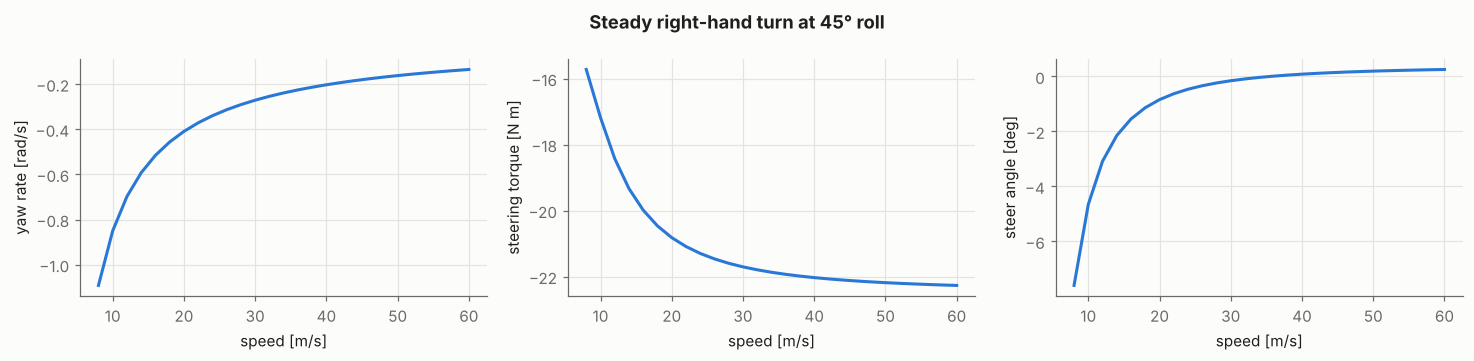

In [10]:
speeds = np.arange(60, 7, -2.0); res = []; z0 = None
for V in speeds:                                   # continuation from high to low speed
    r_ = system.steady_state(V, rad(45), z0=z0); z0 = r_["z"]; res.append(r_)
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.3))
ax[0].plot(speeds, [r_["yaw_rate"] for r_ in res]); ax[0].set_ylabel("yaw rate [rad/s]")
ax[1].plot(speeds, [r_["Tsteer"] for r_ in res]); ax[1].set_ylabel("steering torque [N m]")
ax[2].plot(speeds, [deg(r_["steer"]) for r_ in res]); ax[2].set_ylabel("steer angle [deg]")
for a in ax: a.set_xlabel("speed [m/s]")
fig.suptitle("Steady right-hand turn at 45° roll", fontweight="bold"); plt.tight_layout()
print("max residual:", max(abs(r_["residual"]).max() for r_ in res))

Yaw rate and steer angle behave as in Fig. 7.10. The steering torque stays negative (into the turn) over the whole range, whereas the thesis finds a sign change at low speed.

## Independent check of the lateral dynamics: the benchmark bicycle
Before looking at stability, the complete chain (kinematics, Kane equations, contact geometry, tyre force application) is tested against the
Whipple benchmark of Meijaard et al. (2007, thesis ref. [2]). `okane/benchmark.py` puts the benchmark parameters into the motorcycle model
(knife-edge wheels, suspension locked by stiff springs, stiff linear slip tyres) and compares eigenvalues.

In [11]:
sysb, db = benchmark.benchmark_system()
lam = benchmark.lateral_eigenvalues(5.0, sysb, db)
print("v = 5 m/s            this model                 Meijaard et al. (2007)")
print(f"  weave      {lam[np.argmax(lam.imag)]:.5f}        {benchmark.WEAVE_5:.5f}")
re = np.sort(lam[abs(lam.imag) < 1e-9].real)
print(f"  capsize    {re[-1]:.5f}                   {benchmark.CAPSIZE_5:.5f}")
print(f"  castering  {re[0]:.5f}                  {benchmark.CASTER_5:.5f}")
lw = benchmark.lateral_eigenvalues(benchmark.V_WEAVE, sysb, db)
print(f"\nweave speed {benchmark.V_WEAVE:.4f} m/s: real part of the weave pair = {lw[np.argmax(lw.imag)].real:.1e}")

v = 5 m/s            this model                 Meijaard et al. (2007)
  weave      -0.77472+4.46558j        -0.77534+4.46487j
  capsize    -0.32267                   -0.32287
  castering  -14.08145                  -14.07839

weave speed 4.2924 m/s: real part of the weave pair = 3.7e-04


Agreement to three digits (the remaining difference is the finite tyre and suspension stiffness). Gyroscopics, trail geometry and force application are therefore right.

## Straight-running stability with the thesis tyres (cf. Section 7.8)
Eigenvalues of the full system (22 mechanical states + 4 relaxation states) linearised about straight running; in-plane modes removed.
The thesis model has no steering damper; a damper of 7 N m s/rad (the value of Sharp et al.) is shown for comparison.

81 linearisations in 18 s


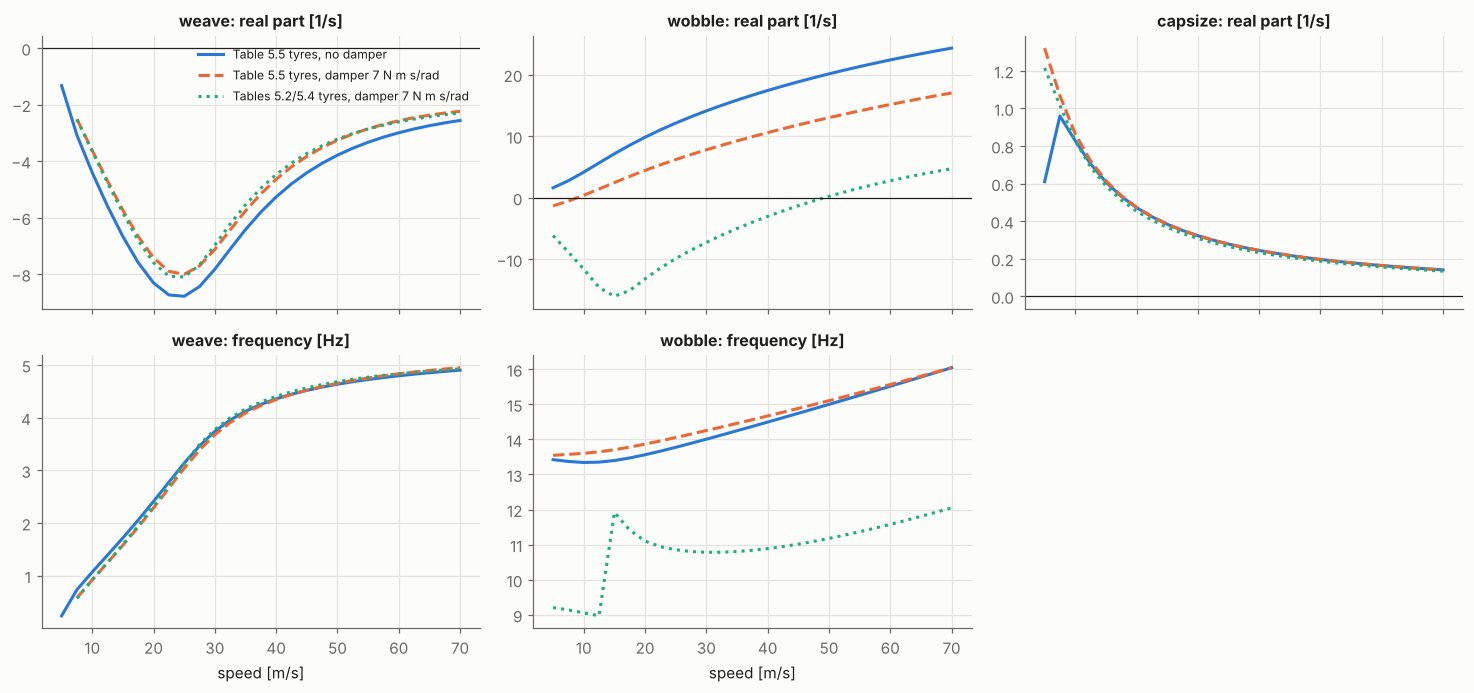

In [12]:
Vs = np.arange(5, 71, 2.5)
cases = [("Table 5.5 tyres, no damper", BikeSystem(bike, F, TyreSet.thesis())),
         ("Table 5.5 tyres, damper 7 N m s/rad", BikeSystem(bike, F, TyreSet.thesis(), c_steer=7.0)),
         ("Tables 5.2/5.4 tyres, damper 7 N m s/rad", BikeSystem(bike, F, TyreSet.thesis(modified=False), c_steer=7.0))]
loci = []
t0 = time.perf_counter()
for name, sy in cases:
    loci.append([lateral_modes(sy, V) for V in Vs])
print(f"{len(cases) * len(Vs)} linearisations in {time.perf_counter() - t0:.0f} s")
fig, ax = plt.subplots(2, 3, figsize=(13.5, 6.4), sharex=True)
for j, (lab, col) in enumerate([("weave", C[0]), ("wobble", C[1]), ("capsize", C[2])]):
    for i, ((name, _), L) in enumerate(zip(cases, loci)):
        re_ = [max([l.real for l, t in m_ if t == lab], default=np.nan) for m_ in L]
        fr_ = [max([l.imag / 2 / np.pi for l, t in m_ if t == lab and l.real == max(x.real for x, tt in m_ if tt == lab)], default=np.nan) for m_ in L]
        ax[0, j].plot(Vs, re_, color=C[i], ls=["-", "--", ":"][i], label=name)
        if lab != "capsize": ax[1, j].plot(Vs, fr_, color=C[i], ls=["-", "--", ":"][i])
    ax[0, j].axhline(0, color="#1f1f1e", lw=0.8); ax[0, j].set_title(f"{lab}: real part [1/s]"); ax[1, j].set_xlabel("speed [m/s]")
    if lab != "capsize": ax[1, j].set_title(f"{lab}: frequency [Hz]")
ax[1, 2].axis("off"); ax[0, 0].legend(fontsize=8); plt.tight_layout()

* **Weave**: frequency rises from about 1 Hz to 5 Hz, damping falls at high speed but the mode stays stable.
* **Capsize**: slowly unstable (time constant of seconds), as usual.
* **Wobble**: 11–16 Hz and **unstable with the Table 5.5 front tyre** – at all speeds without a damper, above about 10 m/s with one. Three things push in that direction and none of them
  is pinned down by the thesis: the very high optimised cornering stiffness with the unchanged carcass stiffness (relaxation length ≈ 0.5 m), the large pneumatic trail of
  the Sharp data (≈ 60–90 mm), and the estimated steering-assembly inertia. A rigid frame is also known to make wobble worst at high speed.
  With the unoptimised tyre data the wobble is stable up to about 50 m/s with the damper.

So for time simulation the steering needs damping (in the thesis the roll-angle PID acts on the steering torque).

## Roll-angle change 0 → 50° at 20 m/s (cf. Fig. 7.11)
Same input shaping as Section 7.4.2: set-point rate limited to 1.2 rad/s, first-order filter τ = 0.15 s. The controller is a **placeholder** PID on the steering
torque (the controls of Section 4.12 are the next session), plus a P controller on rear axle torque for speed and a 10 N m s/rad steering damper.

6 s simulated in 31 s (RK4, 800 Hz)
counter-steer peak +0.42° (to the left) at t = 0.44 s; front Fy minimum -49 N
final: roll 49.9°, steer -0.82°, yaw rate -0.474 rad/s   (thesis: steer ≈ −0.8°, yaw rate −0.457 rad/s)


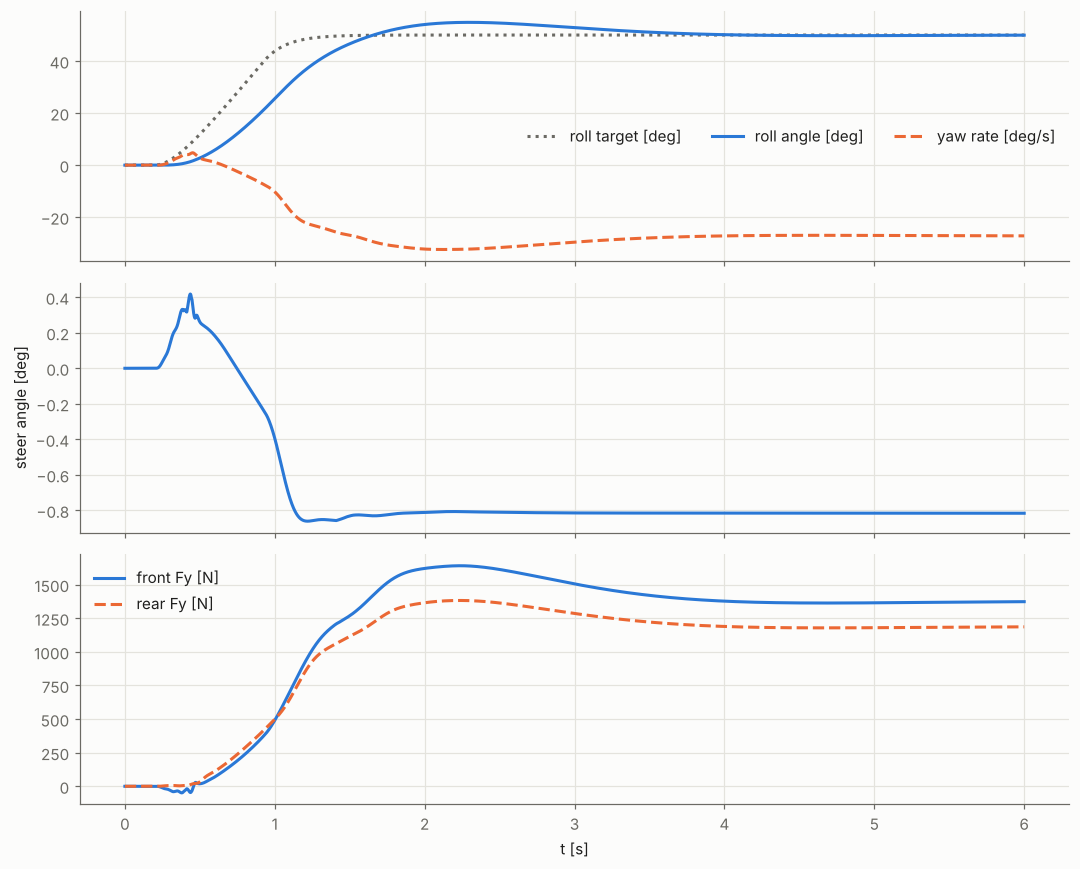

In [13]:
dt, T_end = 1 / 800, 6.0; n = int(T_end / dt); tg = dt * np.arange(n + 2)
ref = np.zeros(n + 2); filt = np.zeros(n + 2)
for i in range(1, n + 2):
    ref[i] = ref[i - 1] + np.clip((rad(50) if tg[i] >= 0.2 else 0.0) - ref[i - 1], -1.2 * dt, 1.2 * dt)
    filt[i] = filt[i - 1] + dt / 0.15 * (ref[i] - filt[i - 1])

class RollPID:
    def __init__(self, Kp=300.0, Ki=300.0, Kd=70.0, Kv=200.0, V=20.0):
        self.Kp, self.Ki, self.Kd, self.Kv, self.V = Kp, Ki, Kd, Kv, V; self.I = 0.0; self.t = 0.0
    def __call__(self, t, k, st):
        q, u = k["q"], k["u"]; e = np.interp(t, tg, filt) - q[8]
        if t > self.t:
            if abs(e) < 0.1: self.I += e * (t - self.t)       # integrate near the target only
            self.t = t
        v = (k["Jv_A"] @ u) @ k["R_M"][:, 0]
        return {"Tsteer": self.Kp * e + self.Ki * self.I - self.Kd * u[8], "Trwy": self.Kv * (v - self.V)}

ctl = RollPID()
sim = BikeSystem(bike, F, TyreSet.thesis(), c_steer=10.0, controls=ctl)
x0 = BikeSystem(bike, F, TyreSet.thesis()).steady_state(20.0, 0.0)["x"]
t0 = time.perf_counter(); tt, X = rk4(sim.rhs, 0.0, x0, dt, n)
print(f"{T_end:.0f} s simulated in {time.perf_counter() - t0:.0f} s (RK4, 800 Hz)")
Ts = np.array([ctl.Kp * (np.interp(t, tg, filt) - x[8]) - ctl.Kd * x[19] for t, x in zip(tt, X)])   # P and D part for plotting

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(tt, deg(filt[:n + 1]), ":", color="#6b6a64", label="roll target [deg]"); ax[0].plot(tt, deg(X[:, 8]), color=C[0], label="roll angle [deg]")
ax[0].plot(tt, deg(X[:, 20]), "--", color=C[1], label="yaw rate [deg/s]"); ax[0].legend(ncol=3)
ax[1].plot(tt, deg(X[:, 10]), color=C[0]); ax[1].set_ylabel("steer angle [deg]")
ax[2].plot(tt, X[:, 23], color=C[0], label="front Fy [N]"); ax[2].plot(tt, X[:, 25], "--", color=C[1], label="rear Fy [N]"); ax[2].legend(); ax[2].set_xlabel("t [s]")
plt.tight_layout()
i1, i2 = np.argmax(deg(X[:, 10])), np.argmax(X[:, 8] > rad(1))
print(f"counter-steer peak {deg(X[i1, 10]):+.2f}° (to the left) at t = {tt[i1]:.2f} s; front Fy minimum {X[:, 23].min():.0f} N")
print(f"final: roll {deg(X[-1, 8]):.1f}°, steer {deg(X[-1, 10]):.2f}°, yaw rate {X[-1, 20]:.3f} rad/s   (thesis: steer ≈ −0.8°, yaw rate −0.457 rad/s)")

The sequence of Fig. 7.11 is reproduced: steering torque to the left steers the wheel left, the front lateral force is briefly negative, the bike rolls right,
the steer angle changes sign and settles near −0.8°. The final state equals the trim solution above.

## Open points
* Unknown in the thesis and filled from Sharp et al. or estimated: $F_{z0}$, trail parameters, $C_x$, $C_y$, radial stiffness, effective rolling radius (here the loaded radius).
* `pCy2` is listed in Tables 5.2/5.4 but does not occur in the printed equation (A.3); it is stored and unused.
* Residual aligning torque $M_{zr}$ ("twisting torque") is implemented (`TyreSet(use_residual=True)`, Sharp data) but off, as in the thesis.
* Next: controls of Sections 4.12–4.13 (PID, Kalman filter, TC/ABS), engine torque map, drag and chain in the loop.